# Ejemplo de optimización con restricciones y multiplicadores de

Lagrange

Modelos computacionales

Ejemplo de resolución paso a paso de un problema de optimización con
restricción utilizando el **método de los Multiplicadores de Lagrange**
desde dos opciones: enfoque primal y enfoque dual.

1.  Problema Primal ([Condiciones
    KKT](https://es.wikipedia.org/wiki/Condiciones_de_Karush-Kuhn-Tucker)).
    Resolvemos simultáneamente todo el sistema de ecuationes que
    describen el punto de corte entre la función objetivo y la
    restricción.

    1.  Derivamos la función Lagrangiana $\mathcal{L}(x,y,\lambda)$
        respecto a todas sus variables ($x$, $y$ y $\lambda$) e
        igualamos a cero.
    2.  Despejamos las variables primales ($x$ e $y$) en función del
        multiplicador ($\lambda$), y se sustituyen en la ecuación de la
        restricción para despejar el valor numérico de $\lambda^*$, y
        finalmente se obtiene el punto óptimo $(x^*, y^*)$.
        Interpretación: Atacas el problema de forma directa resolviendo
        el sistema de ecuaciones simultáneas que dictan el punto de
        tangencia entre las curvas de nivel de la función objetivo y la
        restricción.

2.  Problema Dual (Minimización de la Función Dual). Descomponemos el
    problema en dos partes (como indica el problema dual
    $\min_\lambda \max_{x,y} \mathcal{L}$):

    1.  Maximización interna: encontrar analíticamente cómo se
        comportarían $x$ e $y$ en función de $\lambda$ maximizando la
        Lagrangiana, lo que te permite construir la función dual
        $g(\lambda)$.
    2.  Minimización externa: minimizar la función dual $g(\lambda)$ con
        respecto a $\lambda$ para hallar el multiplicador óptimo
        $\lambda^*$.

## 1. Definición del Problema

Función objetivo a maximizar:

$$f(x, y) = 16 - (x^2 + y^2)$$

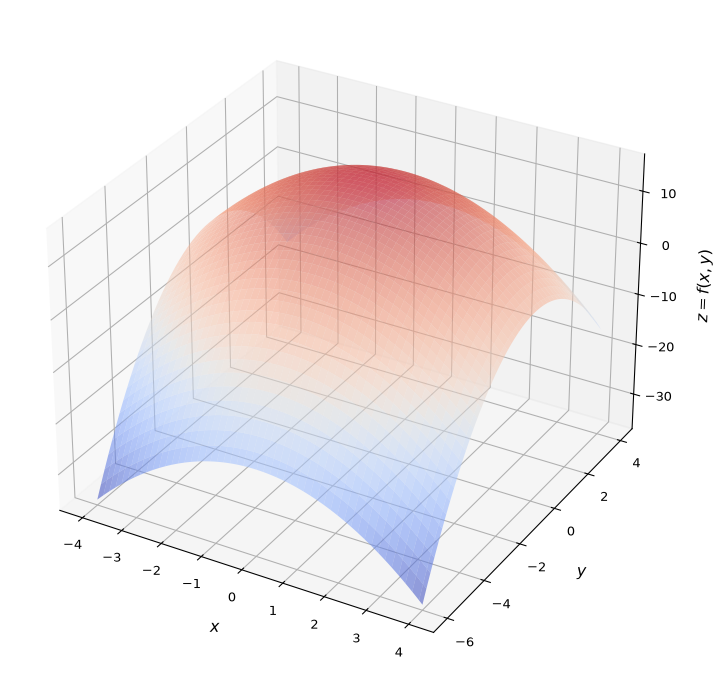

In [1]:
import numpy as np
import matplotlib.pyplot as plt


# Crear la figura 3D
fig = plt.figure(figsize=(13, 9))
ax = fig.add_subplot(111, projection='3d')

# 1. Superficie completa del paraboloide f(x,y) = 16 - (x^2 + y^2)
x = np.linspace(-4, 4, 100)
y = np.linspace(-6, 4, 100)
X, Y = np.meshgrid(x, y)
Z = 16 - (X**2 + Y**2)

# Graficar la superficie objetivo
surf = ax.plot_surface(X, Y, Z, cmap='coolwarm', alpha=0.55, edgecolor='none', antialiased=True)

# Etiquetas y formato de los ejes
ax.set_xlabel('$x$', fontsize=12, fontweight='bold', labelpad=10)
ax.set_ylabel('$y$', fontsize=12, fontweight='bold', labelpad=10)
ax.set_zlabel('$z=f(x, y)$', fontsize=12, fontweight='bold', labelpad=10)


# Añadir barra de colores y leyenda
#fig.colorbar(surf, shrink=0.4, aspect=5, label='Valor de f(x,y)')
#ax.legend(loc='upper left', fontsize=10)

plt.show()


Función de restricción:

$$g(x, y) = 2x - y = 4 \implies 2x - y - 4 = 0$$

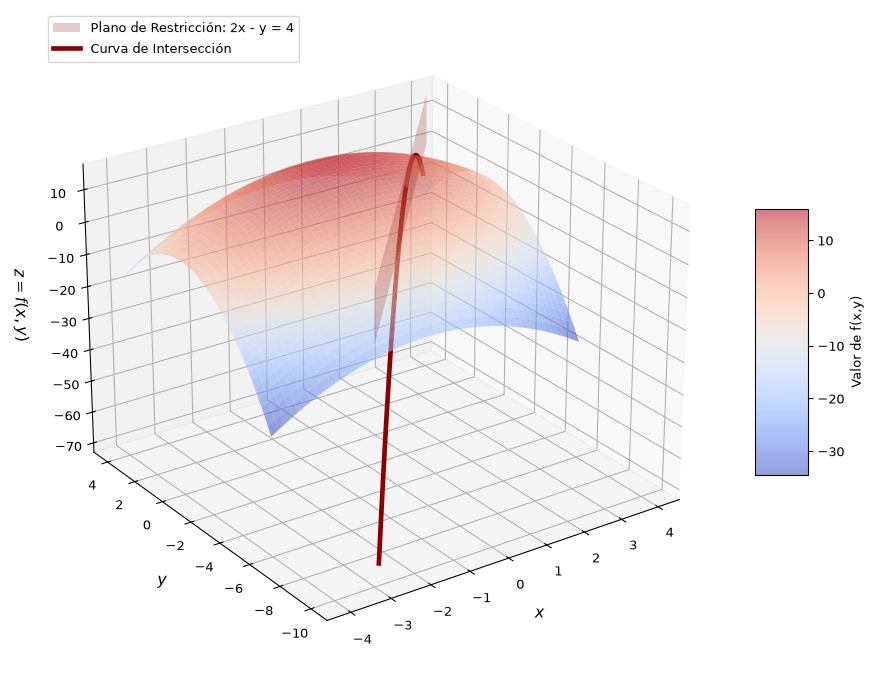

In [2]:
import numpy as np
import matplotlib.pyplot as plt

# Crear la figura 3D
fig = plt.figure(figsize=(13, 9))
ax = fig.add_subplot(111, projection='3d')

# 1. Superficie completa del paraboloide f(x,y) = 16 - (x^2 + y^2)
x = np.linspace(-4, 4, 100)
y = np.linspace(-6, 4, 100)
X, Y = np.meshgrid(x, y)
Z = 16 - (X**2 + Y**2)

# Graficar la superficie objetivo
surf = ax.plot_surface(X, Y, Z, cmap='coolwarm', alpha=0.55, edgecolor='none', antialiased=True)

# 2. Plano vertical transparente para la restricción: 2x - y = 4 => y = 2x - 4
# Como el plano es vertical (independiente de z), usamos una malla en X y Z.
x_plane = np.linspace(-3, 4, 50)
z_plane = np.linspace(0, 16, 50)
X_pl, Z_pl = np.meshgrid(x_plane, z_plane)
Y_pl = 2 * X_pl - 4

# Graficar el plano de restricción transparente
ax.plot_surface(X_pl, Y_pl, Z_pl, color='red', alpha=0.2, edgecolor='none', label='Plano de Restricción: 2x - y = 4')

# 3. Curva de intersección (la restricción proyectada sobre la superficie)
x_constr = np.linspace(-2.5, 3.5, 100)
y_constr = 2 * x_constr - 4
z_constr = 16 - (x_constr**2 + y_constr**2)
ax.plot(x_constr, y_constr, z_constr, color='darkred', linewidth=3.5, label='Curva de Intersección')

# Etiquetas y formato de los ejes
ax.set_xlabel('$x$', fontsize=12, fontweight='bold', labelpad=10)
ax.set_ylabel('$y$', fontsize=12, fontweight='bold', labelpad=10)
ax.set_zlabel('$z=f(x, y)$', fontsize=12, fontweight='bold', labelpad=10)


#ax.set_title('Superficie, Plano de Restricción y Punto Óptimo (Lagrange)', fontsize=14, fontweight='bold')


# Añadir barra de colores y leyenda
fig.colorbar(surf, shrink=0.4, aspect=5, label='Valor de f(x,y)')
ax.legend(loc='upper left', fontsize=10)

# Ajustar la perspectiva de la cámara para apreciar el corte del plano con el paraboloide
ax.view_init(elev=25, azim=-125)

plt.show()

Función Lagrangiana:

$$\mathcal{L}(x, y, \lambda) = 16 - (x^2 + y^2) + \lambda(2x - y - 4)$$

## 2. Solución Primal mediante Multiplicadores de Lagrange

Para encontrar los puntos críticos, igualamos las derivadas parciales de
$\mathcal{L}(x, y, \lambda)$ a cero:

1.  Derivada respecto a $x$:

<span id="eq-dx">$$\frac{\partial \mathcal{L}}{\partial x} = -2x + 2\lambda = 0 \implies x = \lambda \qquad(1)$$</span>

1.  Derivada respecto a $y$:

<span id="eq-dy">$$\frac{\partial \mathcal{L}}{\partial y} = -2y - \lambda = 0 \implies y = -\frac{\lambda}{2} \qquad(2)$$</span>

1.  Derivada respecto a $\lambda$ (la restricción original):

<span id="eq-dlambda">$$\frac{\partial \mathcal{L}}{\partial \lambda} = 2x - y - 4 = 0 \qquad(3)$$</span>

### Sustitución para encontrar $\lambda$, $x$ e $y$:

Sustituimos $x = \lambda$ y $y = -\frac{\lambda}{2}$ en la restricción
de <a href="#eq-dlambda" class="quarto-xref">Ecuación 3</a>:

$$2(\lambda) - \left(-\frac{\lambda}{2}\right) = 4$$

$$2\lambda + \frac{\lambda}{2} = 4$$

$$\frac{5\lambda}{2} = 4 \implies \lambda = \frac{8}{5} = 1.6$$

Ahora calculamos los valores óptimos de $x$ e $y$ en
<a href="#eq-dx" class="quarto-xref">Ecuación 1</a> e
<a href="#eq-dy" class="quarto-xref">Ecuación 2</a>:

-   $x^* = \frac{8}{5} = 1.6$
-   $y^* = -\frac{1}{2} \cdot \left(\frac{8}{5}\right) = -\frac{4}{5} = -0.8$

## 3. Resolución desde la Perspectiva Dual

El problema dual se plantea como:

$$\min_{\lambda} g(\lambda) \quad \text{donde} \quad g(\lambda) = \max_{x,y} \mathcal{L}(x, y, \lambda)$$

Primero, encontrar la función dual
$g(\lambda) = \max_{x,y} \mathcal{L}(x, y, \lambda)$

Expresamos $x$ e $y$ en función de $\lambda$ que maximizan
$\mathcal{L}$:

$$x(\lambda) = \lambda, \quad y(\lambda) = -\frac{\lambda}{2}$$

Sustituimos estos valores en la función Lagrangiana
$\mathcal{L}(x, y, \lambda)$:

$$g(\lambda) = 16 - \left(\lambda^2 + \left(-\frac{\lambda}{2}\right)^2\right) + \lambda\left(2\lambda - \left(-\frac{\lambda}{2}\right) - 4\right)$$

$$g(\lambda) = 16 - \left(\lambda^2 + \frac{\lambda^2}{4}\right) + \lambda\left(\frac{5\lambda}{2} - 4\right)$$

$$g(\lambda) = 16 - \frac{5\lambda^2}{4} + \frac{5\lambda^2}{2} - 4\lambda$$

$$g(\lambda) = 16 + \frac{5\lambda^2}{4} - 4\lambda$$

Segundo, minimizar la función dual $g(\lambda)$ sobre $\lambda$

Para encontrar el mínimo de $g(\lambda)$, derivamos respecto a $\lambda$
e igualamos a cero:

$$g'(\lambda) = \frac{5}{2}\lambda - 4 = 0 \implies \lambda^* = \frac{8}{5}$$

Esto nos da los mismos valores óptimos para $x^* = \frac{8}{5} = 1.6$ e
$y^* = -\frac{4}{5} = -0.8$

Dado que $g''(\lambda) = \frac{5}{2} > 0$, este punto representa un
**mínimo estricto** para la función dual.

## 4. Resultado final y valor máximo

Evaluamos la función objetivo $f(x, y)$ en el punto óptimo
$(x^*, y^*) = \left(\frac{8}{5}, -\frac{4}{5}\right)$:

$$f\left(\frac{8}{5}, -\frac{4}{5}\right) = 16 - \left(\left(\frac{8}{5}\right)^2 + \left(-\frac{4}{5}\right)^2\right)$$

$$f\left(\frac{8}{5}, -\frac{4}{5}\right) = 16 - \left(\frac{64}{25} + \frac{16}{25}\right)$$

$$f\left(\frac{8}{5}, -\frac{4}{5}\right) = 16 - \frac{80}{25} = 16 - 3.2 = 12.8$$

## Resumen de la solución y por qué son iguales:

-   **Punto Óptimo:** $(x^*, y^*) = (1.6, -0.8)$ o
    $\left(\frac{8}{5}, -\frac{4}{5}\right)$
-   **Multiplicador de Lagrange óptimo:** $\lambda^* = 1.6$ o
    $\frac{8}{5}$
-   **Valor Máximo Alcanzado:** $f(x^*, y^*) = 12.8$ o $\frac{64}{5}$

Las soluciones de las formas primal y dual coinciden porque la función
objetivo es convexa y la restricción es lineal, esto hace que se cumpla
la dualidad fuerte (el duality gap es cero).

Más información en
<https://en.wikipedia.org/wiki/Duality_(optimization)>

## Visualización de la solución

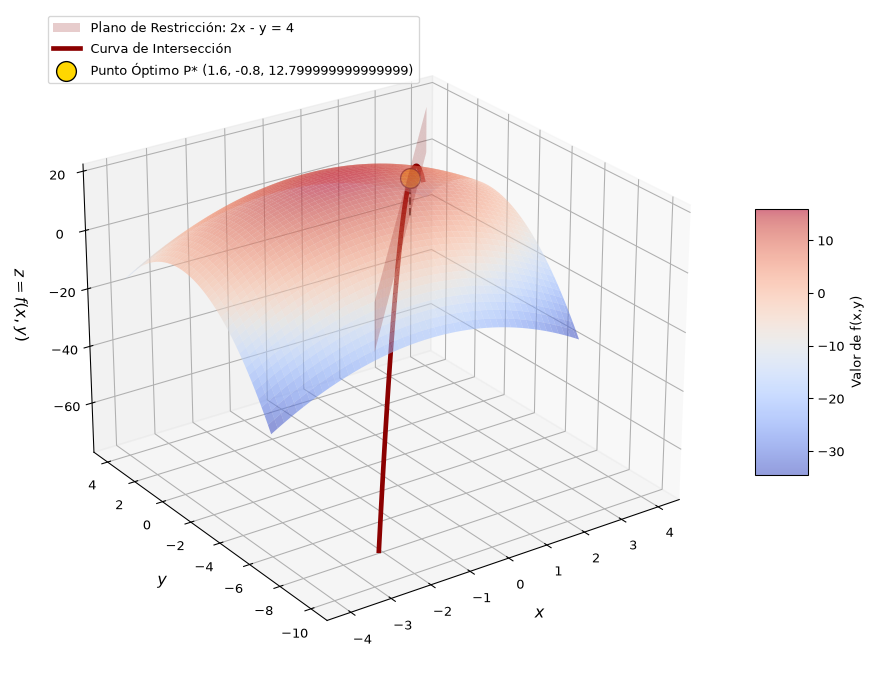

In [3]:
import numpy as np
import matplotlib.pyplot as plt

# Crear la figura 3D
fig = plt.figure(figsize=(13, 9))
ax = fig.add_subplot(111, projection='3d')

# 1. Superficie completa del paraboloide f(x,y) = 16 - (x^2 + y^2)
x = np.linspace(-4, 4, 100)
y = np.linspace(-6, 4, 100)
X, Y = np.meshgrid(x, y)
Z = 16 - (X**2 + Y**2)

# Graficar la superficie objetivo
surf = ax.plot_surface(X, Y, Z, cmap='coolwarm', alpha=0.55, edgecolor='none', antialiased=True)

# 2. Plano vertical transparente para la restricción: 2x - y = 4 => y = 2x - 4
# Como el plano es vertical (independiente de z), usamos una malla en X y Z.
x_plane = np.linspace(-3, 4, 50)
z_plane = np.linspace(0, 16, 50)
X_pl, Z_pl = np.meshgrid(x_plane, z_plane)
Y_pl = 2 * X_pl - 4

# Graficar el plano de restricción transparente
ax.plot_surface(X_pl, Y_pl, Z_pl, color='red', alpha=0.2, edgecolor='none', label='Plano de Restricción: 2x - y = 4')

# 3. Curva de intersección (la restricción proyectada sobre la superficie)
x_constr = np.linspace(-2.5, 3.5, 100)
y_constr = 2 * x_constr - 4
z_constr = 16 - (x_constr**2 + y_constr**2)
ax.plot(x_constr, y_constr, z_constr, color='darkred', linewidth=3.5, label='Curva de Intersección')





# 4. Punto óptimo encontrado: (1.6, -0.8, 12.8)
x_opt = 1.6
y_opt = -0.8
z_opt = 16 - (x_opt**2 + y_opt**2)

# Señalar el punto óptimo
ax.scatter([x_opt], [y_opt], [z_opt], color='gold', s=220, zorder=5, edgecolors='black', label=f'Punto Óptimo P* ({x_opt}, {y_opt}, {z_opt})')

# Línea punteada desde el punto óptimo hasta el plano XY para referencia visual
ax.plot([x_opt, x_opt], [y_opt, y_opt], [0, z_opt], color='black', linestyle='--', linewidth=1.5, alpha=0.7)

# Etiquetas y formato de los ejes
ax.set_xlabel('$x$', fontsize=12, fontweight='bold', labelpad=10)
ax.set_ylabel('$y$', fontsize=12, fontweight='bold', labelpad=10)
ax.set_zlabel('$z=f(x, y)$', fontsize=12, fontweight='bold', labelpad=10)


#ax.set_title('Superficie, Plano de Restricción y Punto Óptimo (Lagrange)', fontsize=14, fontweight='bold')

# Añadir barra de colores y leyenda
fig.colorbar(surf, shrink=0.4, aspect=5, label='Valor de f(x,y)')
ax.legend(loc='upper left', fontsize=10)

# Ajustar la perspectiva de la cámara para apreciar el corte del plano con el paraboloide
ax.view_init(elev=25, azim=-125)

plt.show()